# Business Problem

As a marketing agency, our primary objective is to maximize the return on investment (ROI) for our clients' advertising campaigns. We
have conducted two ad campagins, one on Facebook and the other on AdWords, and we need to determine which platform yield better results in 
terms of clicks, conversion and overall cost-effectiveness. By identifying the most effective platform, we can allocate our resources more efficiently and optimize our advertising strategies to deliver better outcomes for our client.

# Research Question

Which ad Platform is more effective in terms of conversions,clicks and overall cost-effectiveness?

# Import Libraries

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import coint
import warnings

warnings.filterwarnings("ignore")


# Data Description

"The dataset comprises a collection of data comparing the performance of two seperate ad campaigns conducted throughout the year 2019. Specifically, the data covers a Facebook Ad campaign and an AdWords Ad campaign. For each day of the year 2019, there is a corresponding row in the dataset, resulting in the total of 365 lines if campaign data to analyze. The dataset includes various performance metrics for each ad campaign, providing insights into their effectiveness and efficiency over time"

Key Features:

* Date
* Ad views
* Ad Clicks
* Ads Conversion
* Cost per Ad
* Click Through Rate (CTR)
* Conversion Rate
* Cost per Click

In [54]:
df=pd.read_csv("Downloads/ad_campaign_2019_dataset.csv")

In [55]:
df.head()

,Date,Facebook Ad Campaign,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,Cost per Facebook Ad,Facebook Click-Through Rate (Clicks / View),Facebook Conversion Rate (Conversions / Clicks),Facebook Cost per Click (Ad Cost / Clicks),AdWords Ad Campaign,AdWords Ad Views,AdWords Ad Clicks,AdWords Ad Conversions,AdWords Cost per Ad,AdWords Click-Through Rate (Clicks / View),AdWords Conversion Rate (Conversions / Clicks),AdWords Cost per Click (Ad Cost / Clicks)
0,1/1/2019,FB_2019,4174,78,28,135,1.87%,35.9%,1.73,AW_2019,4294,131,18,225,3.05%,13.74%,1.72
1,1/2/2019,FB_2019,4507,82,30,157,1.82%,36.59%,1.91,AW_2019,5539,121,11,230,2.18%,9.09%,1.90
2,1/3/2019,FB_2019,1860,20,9,73,1.08%,45.0%,3.65,AW_2019,5255,128,17,232,2.44%,13.28%,1.81
3,1/4/2019,FB_2019,2294,16,5,130,0.7%,31.25%,8.12,AW_2019,6610,202,12,249,3.06%,5.94%,1.23
4,1/5/2019,FB_2019,2130,58,13,169,2.72%,22.41%,2.91,AW_2019,4607,48,7,103,1.04%,14.58%,2.15


In [56]:
#Check no of rows and columns
df.shape

(365, 17)

In [57]:
# Check missing values
df.isnull().sum().sum()

np.int64(0)

In [58]:
#datatypes of column
df.dtypes

Date                                                object
Facebook Ad Campaign                                object
Facebook Ad Views                                    int64
Facebook Ad Clicks                                   int64
Facebook Ad Conversions                              int64
Cost per Facebook Ad                                 int64
Facebook Click-Through Rate (Clicks / View)         object
Facebook Conversion Rate (Conversions / Clicks)     object
Facebook Cost per Click (Ad Cost / Clicks)         float64
AdWords Ad Campaign                                 object
AdWords Ad Views                                     int64
AdWords Ad Clicks                                    int64
AdWords Ad Conversions                               int64
AdWords Cost per Ad                                  int64
AdWords Click-Through Rate (Clicks / View)          object
AdWords Conversion Rate (Conversions / Clicks)      object
AdWords Cost per Click (Ad Cost / Clicks)          float

In [59]:
#Convert date column datatype
df['Date']=pd.to_datetime(df['Date'])

In [60]:
#descriptive stats of the data
df.describe()

,Date,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,Cost per Facebook Ad,Facebook Cost per Click (Ad Cost / Clicks),AdWords Ad Views,AdWords Ad Clicks,AdWords Ad Conversions,AdWords Cost per Ad,AdWords Cost per Click (Ad Cost / Clicks)
count,365,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2019-07-02 00:00:00,3075.213699,55.602740,18.383562,119.761644,3.432603,4937.268493,121.643836,11.660274,163.161644,1.602521
min,2019-01-01 00:00:00,1001.000000,6.000000,1.000000,50.000000,0.420000,3001.000000,37.000000,2.000000,70.000000,0.290000
25%,2019-04-02 00:00:00,2153.000000,30.000000,9.000000,82.000000,1.450000,3956.000000,84.000000,7.000000,116.000000,0.950000
50%,2019-07-02 00:00:00,3047.000000,49.000000,16.000000,116.000000,2.390000,4956.000000,113.000000,10.000000,161.000000,1.360000
75%,2019-10-01 00:00:00,4029.000000,76.000000,24.000000,157.000000,3.840000,5936.000000,158.000000,15.000000,214.000000,1.980000
max,2019-12-31 00:00:00,4993.000000,144.000000,65.000000,199.000000,33.000000,6965.000000,259.000000,35.000000,249.000000,5.570000
std,NaN,1114.925887,32.138924,12.292933,43.659845,3.580742,1147.699275,49.345432,6.429643,53.504377,0.943832


# Comparing Campaigns Performance

### Clicks and Conversion


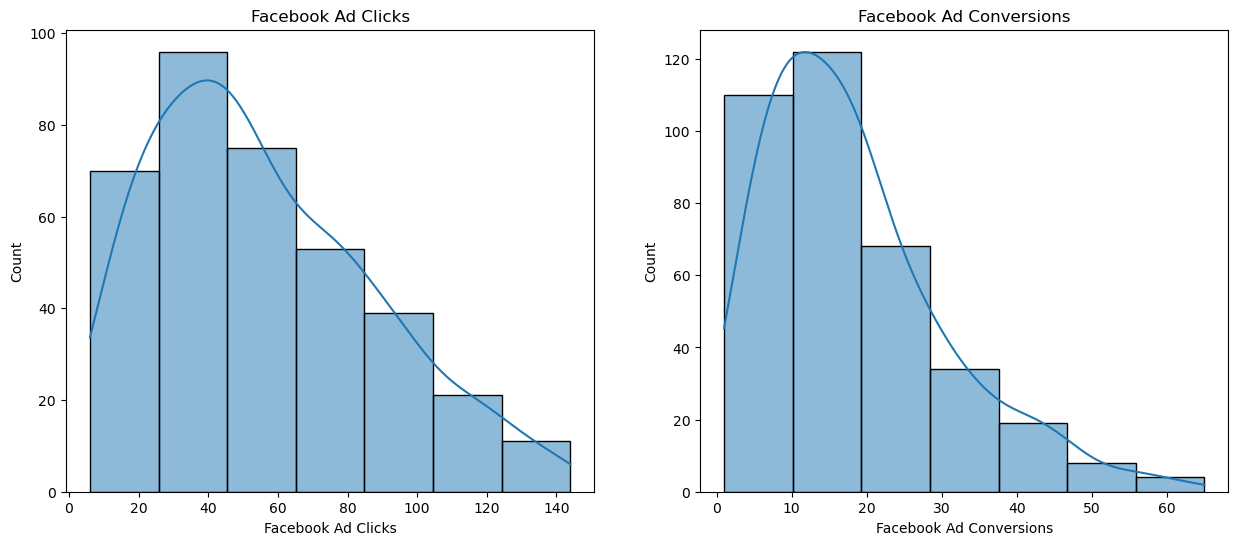

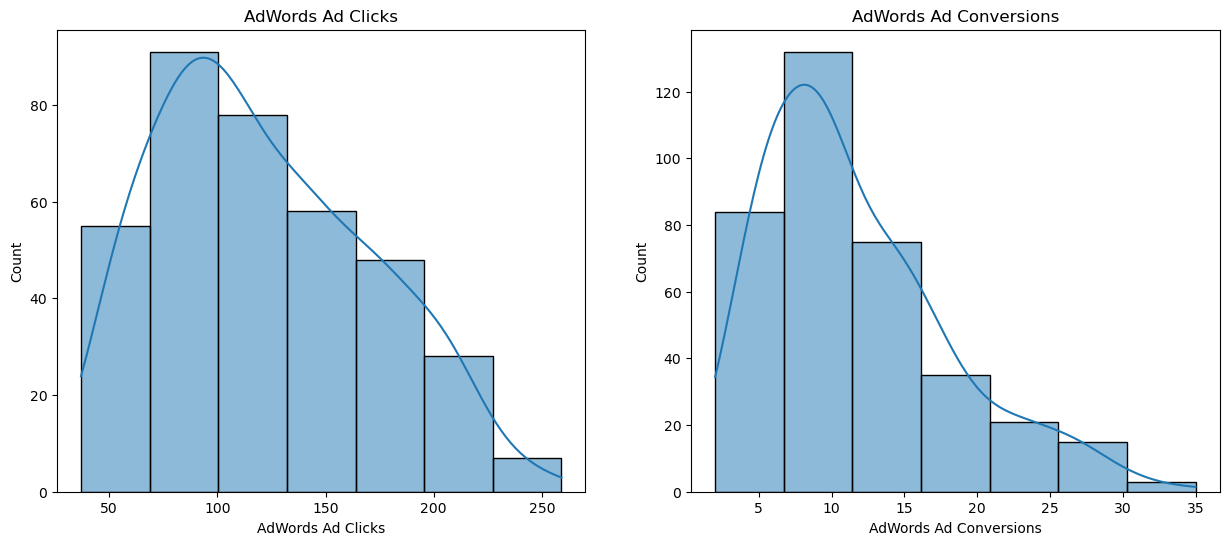

In [61]:
# Distribution of Clicks and Conversion
plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
plt.title('Facebook Ad Clicks')
sns.histplot(df['Facebook Ad Clicks'], bins=7, edgecolor='k', kde=True)
plt.subplot(1,2,2)
plt.title('Facebook Ad Conversions')
sns.histplot(df['Facebook Ad Conversions'], bins=7, edgecolor='k', kde=True)
plt.show()


plt.figure(figsize=(15,6))
plt.subplot(1,2,1)
plt.title('AdWords Ad Clicks')
sns.histplot(df['AdWords Ad Clicks'], bins=7, edgecolor='k', kde=True)
plt.subplot(1,2,2)
plt.title('AdWords Ad Conversions')
sns.histplot(df['AdWords Ad Conversions'], bins=7, edgecolor='k', kde=True)
plt.show()




## Conclusion

AdWords drives higher traffic but with lower conversion efficiency, while Facebook generates fewer clicks but have more conversion efficiency as compared to AdWords. This indicates that Facebook attracts higher-quality users, whereas AdWords is better suited for reach and awareness campaigns but not for conversion.

#### How frequently do we observe days with high number of conversions compared to days with low number of conversion?

In [62]:
# creating function to calculate the category for the conversions
def create_conversion_category(conversion_col):
    category=[]
    for conversion in df[conversion_col]:
        if conversion < 6:
            category.append('less than 6')
        elif 6 <= conversion < 11:
            category.append('6-10')
        elif 11 <= conversion < 16:
            category.append('10-15')
        else:
            category.append('more than 15')
    return category

#Applying function
df['Facebook Conversion Category']=create_conversion_category('Facebook Ad Conversions')
df['AdWords Conversion Category']=create_conversion_category('AdWords Ad Conversions')

In [63]:
df[['Facebook Ad Conversions','Facebook Conversion Category', 'AdWords Ad Conversions','AdWords Conversion Category']].head()

,Facebook Ad Conversions,Facebook Conversion Category,AdWords Ad Conversions,AdWords Conversion Category
0,28,more than 15,18,more than 15
1,30,more than 15,11,10-15
2,9,6-10,17,more than 15
3,5,less than 6,12,10-15
4,13,10-15,7,6-10


In [64]:
df['Facebook Conversion Category'].value_counts()

Facebook Conversion Category
more than 15    189
6-10             67
10-15            66
less than 6      43
Name: count, dtype: int64

In [65]:
facebook=pd.DataFrame(df['Facebook Conversion Category']).value_counts().reset_index().rename(columns={'Facebook Conversion Category':'Category'})
facebook

,Category,count
0,more than 15,189
1,6-10,67
2,10-15,66
3,less than 6,43


In [66]:
df['AdWords Conversion Category'].value_counts()

AdWords Conversion Category
6-10            135
10-15            89
more than 15     84
less than 6      57
Name: count, dtype: int64

In [41]:
adwords=pd.DataFrame(df['AdWords Conversion Category']).value_counts().reset_index().rename(columns={'AdWords Conversion Category':'Category'})
adwords

,Category,count
0,6-10,135
1,10-15,89
2,more than 15,84
3,less than 6,57


In [42]:
category_df=pd.merge(facebook, adwords, on='Category', how='outer')
category_df

,Category,count_x,count_y
0,10-15,66,89
1,6-10,67,135
2,less than 6,43,57
3,more than 15,189,84


In [43]:
category_df=category_df.iloc[[2,1,0,3]]
category_df

,Category,count_x,count_y
2,less than 6,43,57
1,6-10,67,135
0,10-15,66,89
3,more than 15,189,84


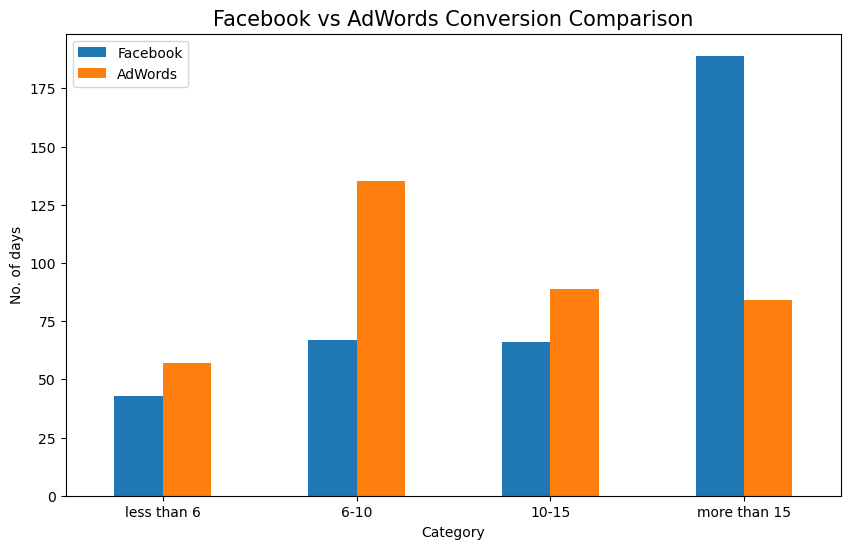

In [44]:
#Plot barcharts
category_df.set_index('Category')[['count_x', 'count_y']].plot(kind='bar', figsize=(10,6), rot=0)

plt.title('Facebook vs AdWords Conversion Comparison',fontsize=15)
plt.xlabel('Category')
plt.ylabel('No. of days')
plt.legend(['Facebook', 'AdWords'])

plt.show()

## Conclusion:
Facebook appears to be more impactful for achieving high conversions, while AdWords provides more moderate and stable performance. Depending on business goals, Facebook can be leveraged for high returns, whereas AdWords can be used for steady and consistent conversions.

### Do more clicks on the ad really lead to more sales?

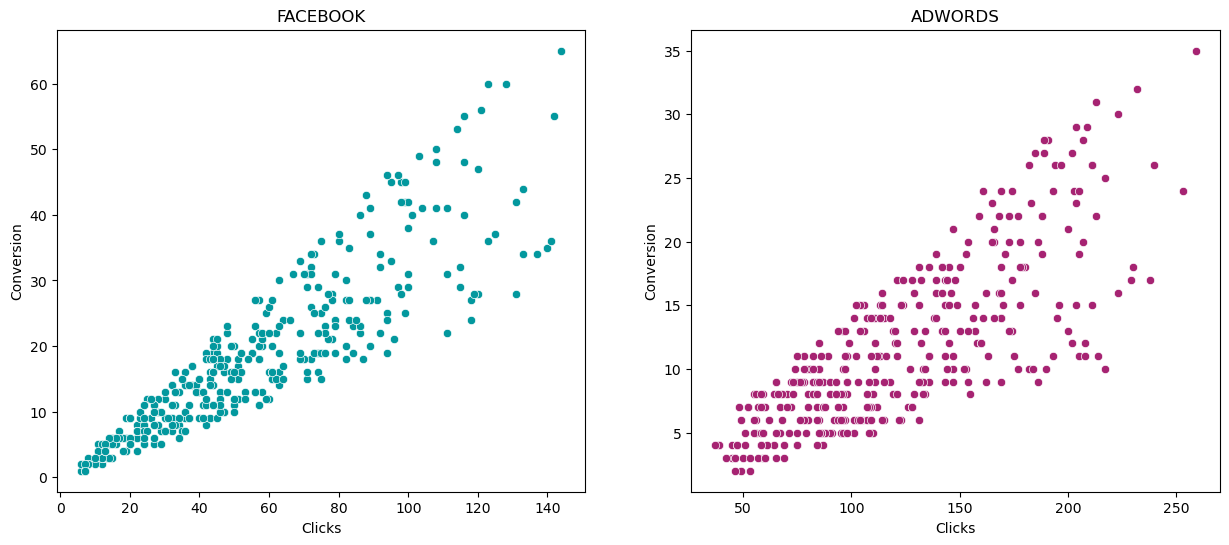

In [45]:
plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.title('FACEBOOK')
sns.scatterplot(x=df['Facebook Ad Clicks'], y=df['Facebook Ad Conversions'], color='#03989E')
plt.xlabel('Clicks')
plt.ylabel('Conversion')

plt.subplot(1,2,2)
plt.title('ADWORDS')
sns.scatterplot(x=df['AdWords Ad Clicks'], y=df['AdWords Ad Conversions'], color='#A62372')
plt.xlabel('Clicks')
plt.ylabel('Conversion')

plt.show()

In [46]:
facebook_corr=df[['Facebook Ad Conversions', 'Facebook Ad Clicks']].corr()
facebook_corr

,Facebook Ad Conversions,Facebook Ad Clicks
Facebook Ad Conversions,1.000000,0.888609
Facebook Ad Clicks,0.888609,1.000000


In [47]:
AdWords_corr=df[['AdWords Ad Conversions', 'AdWords Ad Clicks']].corr()
AdWords_corr

,AdWords Ad Conversions,AdWords Ad Clicks
AdWords Ad Conversions,1.000000,0.793478
AdWords Ad Clicks,0.793478,1.000000


In [48]:
print('Correlation Coeff \n -------------')
print('Facebook:',round(facebook_corr.values[0,1],2))
print('AdWords:',round(AdWords_corr.values[0,1],2))   

Correlation Coeff 
 -------------
Facebook: 0.89
AdWords: 0.79


### Conclusion:

* There is a strong positive relationship between clicks and conversions for both campaigns, meaning more clicks generally lead to more sales.
* Facebook (0.89) shows a stronger correlation than AdWords (0.79), indicating better efficiency in converting clicks into actual customers.
* This suggests Facebook delivers higher-quality traffic, while AdWords focuses more on generating higher volume but less consistent conversions.

# Hypothesis Testing

`Hypothesis`:Advertising on Facebook will result in a greater number of conversions compared to advertising on AdWords.

`Null Hypothesis (H0)`: There is no difference in the number of conversions between Facebook and AdWords, or the number of conversions
                        from AdWords is greater than or equal to those Facebook.

`Alternative Hypothesis:`The number of conversions from Facebook is greater than the number of conversions from AdWords.

IF
    p < 0.05 or equal : Reject Null Hypothesis
    
    p > 0.05: Fail to Reject

In [49]:
print('Mean Conversion:  \n ----------------')
print('Facebook :', round(df['Facebook Ad Conversions'].mean(),2))
print('AdWords :', round(df['AdWords Ad Conversions'].mean(),2))

t_stats,p_val=st.ttest_ind(a=df['Facebook Ad Conversions'] , b=df['AdWords Ad Conversions'], equal_var=False)
print('\nT_Statistic:', t_stats , '\np_value:',p_val)

#Comparing
if p_val < 0.05:
    print('\nP value is less than siginificant value, Reject Null Hypothesis')
else:
    print('\nP value is greater than siginificant value, Fail to Reject/Accept Null Hypothesis')

Mean Conversion:  
 ----------------
Facebook : 18.38
AdWords : 11.66

T_Statistic: 9.258951420473457 
p_value: 4.606760849015918e-19

P value is less than siginificant value, Reject Null Hypothesis


### Conclusion:

* The average conversions from Facebook (18.38) are significantly higher than AdWords (11.66), indicating better overall performance.
* The p-value (4.60e-19) is far below the significance level, meaning the result is statistically significant and not due to chance.
* Therefore, we reject the null hypothesis and conclude that Facebook ads generate significantly more conversions than AdWords.
* With the Help of A/B testing and Hypothesis we clearly knows that Facebook Ads are more powerful for our Business' sales and conversions


# Regression Analysis

#### Prediction
What will happen when I do go with Facebook Ad? How many facebook ad conversions can I expect given a certain number of facebook ad clicks?

In [50]:
# Independent Variable
X=df[['Facebook Ad Clicks']]

# Dependent Variable
Y=df[['Facebook Ad Conversions']]

# Intializing and fitting Linear Regression Model
reg_model=LinearRegression()
reg_model.fit(X,Y)
prediction=reg_model.predict(X)

# Model Evalution
r2=r2_score(Y,prediction) * 100
mse=mean_squared_error(Y,prediction)   

print('Accuracy (R2 Score):',round(r2,2),'%')
print('Mean square error:' ,round(mse,2))


Accuracy (R2 Score): 78.96 %
Mean square error: 31.7


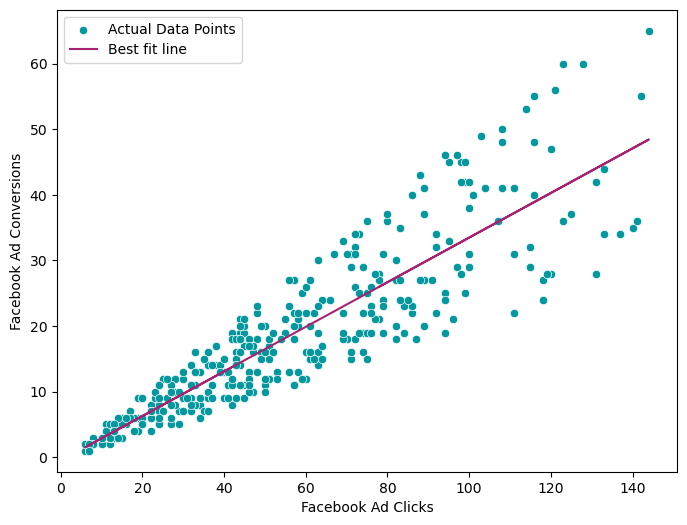

In [51]:
plt.figure(figsize=(8,6))

# Fix 1: correct y
sns.scatterplot(x=df['Facebook Ad Clicks'], 
                y=df['Facebook Ad Conversions'], 
                color='#03989E', 
                label='Actual Data Points')

# Fix 2: flatten prediction
prediction = prediction.flatten()

plt.plot(df['Facebook Ad Clicks'], prediction, 
         color='#A62372', 
         label='Best fit line')

plt.legend()
plt.show()


In [52]:
print(f'for (100) Clicks, Expected Conversion: {round(reg_model.predict([[100]])[0] [0],2)}')
print(f'for (140) Clicks, Expected Conversion: {round(reg_model.predict([[140]])[0] [0],2)}')

for (100) Clicks, Expected Conversion: 33.47
for (140) Clicks, Expected Conversion: 47.07


## Conclusion:

* The model has reasonably good predictive power, with a R2 Score of 78.96%. This suggest that it can efficently predict Facebook ad conversion    based on the number of Facebook Ad Clicks.
* With the insights provided by Linear Regression model, businesses can make informed decision about resource allocation,budget planning,and     campiagn optimization

# Analyzing Facebook Campaign metrices over time

In [68]:
# Cleaning data and removing unwanted symbols
df['Facebook Click-Through Rate (Clicks / View)']=df['Facebook Click-Through Rate (Clicks / View)'].apply(lambda x:float(x[:-1]))
df['Facebook Conversion Rate (Conversions / Clicks)']=df['Facebook Conversion Rate (Conversions / Clicks)'].apply(lambda x:float(x[:-1]))

In [74]:
# Filtering data for facebook campagins

df=df[['Date',
      'Facebook Ad Views','Facebook Ad Clicks','Facebook Ad Conversions','Cost per Facebook Ad',
      'Facebook Click-Through Rate (Clicks / View)','Facebook Conversion Rate (Conversions / Clicks)',
        'Facebook Cost per Click (Ad Cost / Clicks)']]
df.head()


,Date,Facebook Ad Views,Facebook Ad Clicks,Facebook Ad Conversions,Cost per Facebook Ad,Facebook Click-Through Rate (Clicks / View),Facebook Conversion Rate (Conversions / Clicks),Facebook Cost per Click (Ad Cost / Clicks)
0,2019-01-01,4174,78,28,135,1.87,35.90,1.73
1,2019-01-02,4507,82,30,157,1.82,36.59,1.91
2,2019-01-03,1860,20,9,73,1.08,45.00,3.65
3,2019-01-04,2294,16,5,130,0.70,31.25,8.12
4,2019-01-05,2130,58,13,169,2.72,22.41,2.91


In [ ]:
df.head()

#### At what times of the month or days of the week do we observe the conversions?

In [75]:
#Extracting months and weekday from date column
df['month']=df['Date'].dt.month
df['week']=df['Date'].dt.weekday

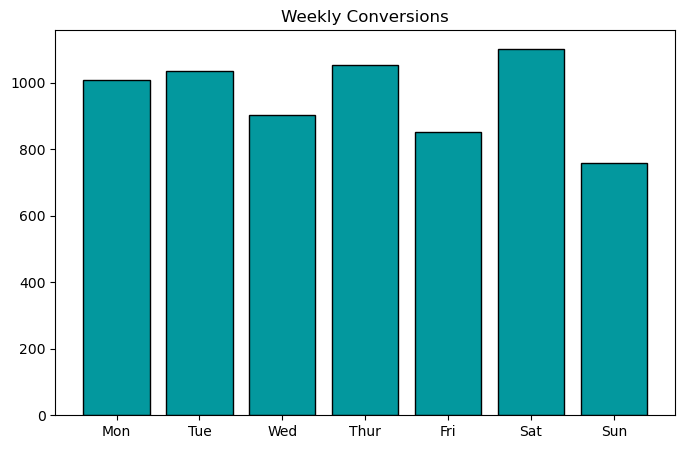

In [77]:
plt.figure(figsize=(8,5))
plt.title('Weekly Conversions')
week_con=df.groupby('week')[['Facebook Ad Conversions']].sum()
week_names=['Mon','Tue','Wed','Thur','Fri','Sat','Sun']
plt.bar(week_names,week_con['Facebook Ad Conversions'], color='#03989E' , edgecolor='k')
plt.show()

## Conclusion:

Conversions are not evenly distributed across the week. Certain days consistently show higher performance, indicating that user engagement and purchase behavior are influenced by day-specific patterns.

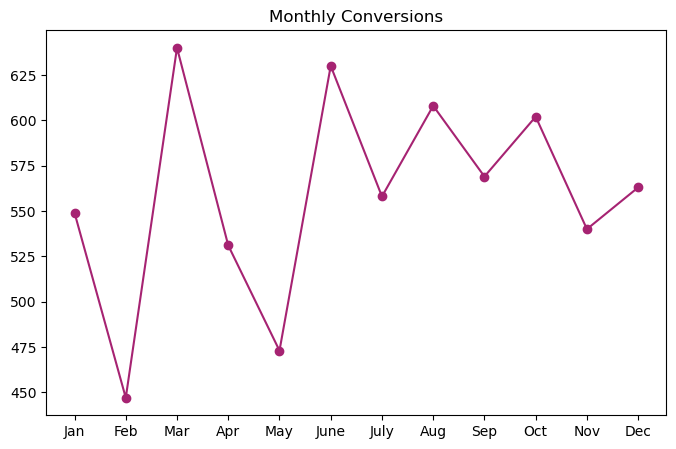

In [78]:
plt.figure(figsize=(8,5))
plt.title('Monthly Conversions')
month_con=df.groupby('month')[['Facebook Ad Conversions']].sum()
mon_names=['Jan','Feb','Mar','Apr','May','June','July','Aug','Sep','Oct','Nov','Dec']
plt.plot(mon_names,month_con['Facebook Ad Conversions'], color='#A62372' , marker='o')
plt.show()

## Conclusion:

Monthly conversion trends show clear seasonality, with strong peaks in specific months and noticeable declines in others. This suggests that customer demand fluctuates due to seasonal behavior, campaigns, or market trends.


##### How does the Cost Per Conversion (CPC) trend over time?

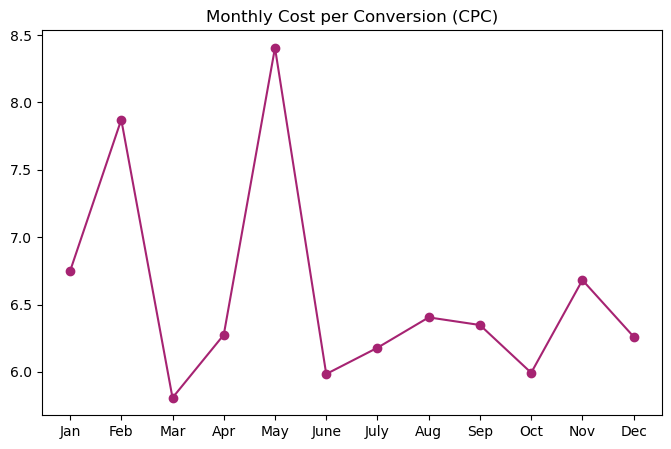

In [83]:
plt.figure(figsize=(8,5))
plt.title('Monthly Cost per Conversion (CPC)')

month_df = df.groupby('month')[['Facebook Ad Conversions','Cost per Facebook Ad']].sum()

month_df['Cost per Conversion'] = month_df['Cost per Facebook Ad'] / month_df['Facebook Ad Conversions']

plt.plot(mon_names, month_df['Cost per Conversion'], color='#A62372', marker='o')

plt.show()

## Conclusion:

* The analysis reveals a strong relationship between conversion volume and cost efficiency. Months with higher conversions (e.g., March and June) also exhibit lower CPC, indicating optimal campaign performance. Conversely, months with lower conversions (e.g., May and February) show higher CPC, suggesting inefficient ad spending. This highlights the importance of aligning budget allocation and campaign strategy with high-performing time periods to maximize ROI.
  
* Higher conversions with lower CPC indicate efficient campaign performance, not necessarily lower spending. It reflects better targeting, timing, and audience engagement rather than reduced budget.